<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/Semana_13_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alumno: **Gizeh Gutierrez**

Matricula: **271752**


In [1]:

from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar archivo
ruta = "/content/drive/MyDrive/ClassFiles/TCGA_InfoWithGrade.csv"
df = pd.read_csv(ruta)


Mounted at /content/drive


In [2]:
# Dimensiones del dataset
print("Shape:", df.shape)
# Estadísticas descriptivas
df.describe()
# Información general
df.info()




Shape: (839, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grade             839 non-null    int64  
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    int64  
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1             839 non-null    int64  
 15  RB1               839 non-null    int64  
 16  NOTCH1            839 non-n

In [3]:
print(df['Grade'].value_counts())

print(df['Gender'].value_counts())

Grade
0    487
1    352
Name: count, dtype: int64
Gender
0    488
1    351
Name: count, dtype: int64


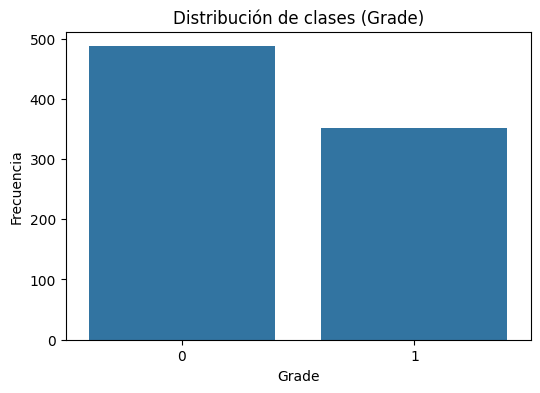

In [4]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Grade')

plt.title('Distribución de clases (Grade)')
plt.xlabel('Grade')
plt.ylabel('Frecuencia')

plt.show()

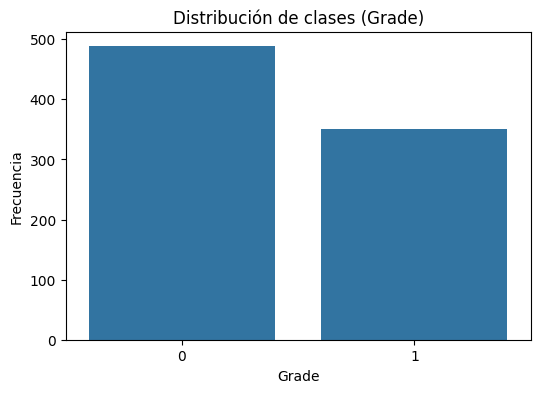

In [5]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Gender')

plt.title('Distribución de clases (Grade)')
plt.xlabel('Grade')
plt.ylabel('Frecuencia')

plt.show()

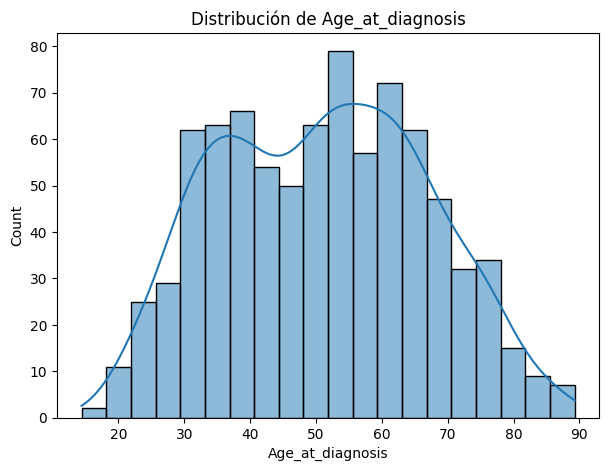

In [6]:
plt.figure(figsize=(7,5))

sns.histplot(
    df['Age_at_diagnosis'],
    bins=20,
    kde=True
)

plt.title('Distribución de Age_at_diagnosis')
plt.show()

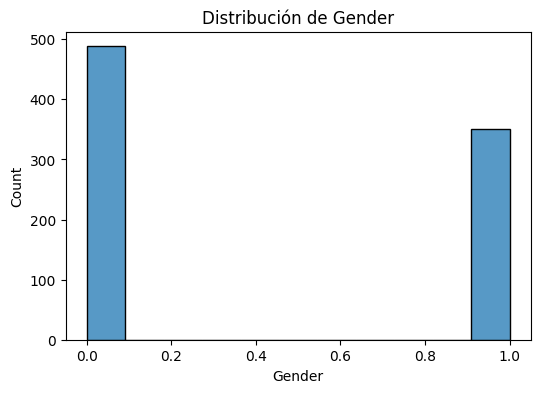

In [7]:
plt.figure(figsize=(6,4))

sns.histplot(df['Gender'])

plt.title('Distribución de Gender')
plt.show()

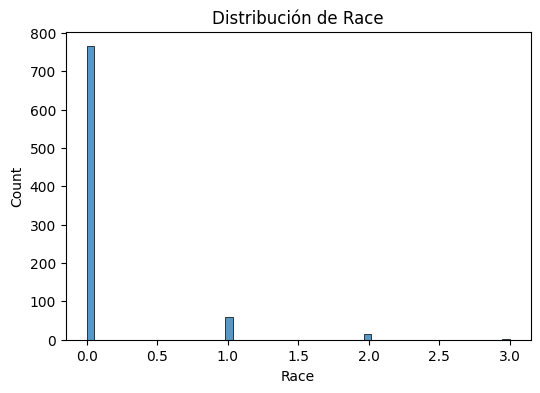

In [8]:
plt.figure(figsize=(6,4))

sns.histplot(df['Race'])

plt.title('Distribución de Race')
plt.show()

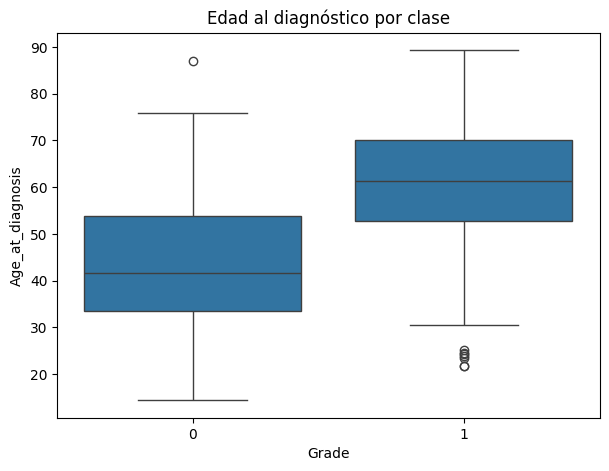

In [9]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x='Grade',
    y='Age_at_diagnosis'
)

plt.title('Edad al diagnóstico por clase')
plt.show()

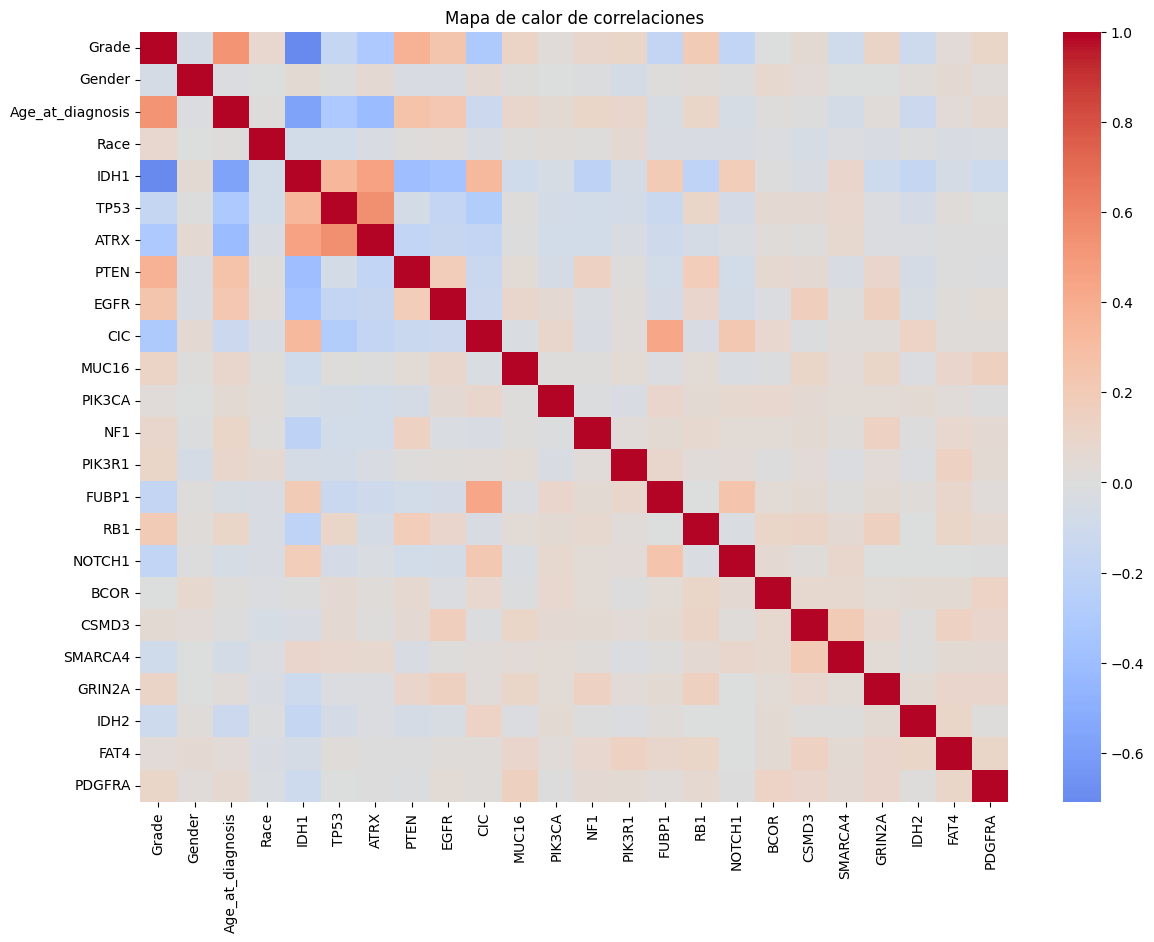

In [10]:
plt.figure(figsize=(14,10))

corr = df.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title('Mapa de calor de correlaciones')
plt.show()

No se observa un desbalance importante entre las clases de Grade. Los atributos que parecen aportar más información son Age_at_diagnosis y las mutaciones genéticas IDH1, TP53, ATRX, PTEN y EGFR, ya que muestran diferencias entre los distintos grados de glioma.

Profundidad: 2
F1 Macro CV: 0.8678
----------------------------------------
Profundidad: 5
F1 Macro CV: 0.8590
----------------------------------------
Profundidad: 10
F1 Macro CV: 0.8170
----------------------------------------
Profundidad: 15
F1 Macro CV: 0.7952
----------------------------------------
Profundidad: 20
F1 Macro CV: 0.7971
----------------------------------------
Profundidad: 25
F1 Macro CV: 0.7956
----------------------------------------
Profundidad: 30
F1 Macro CV: 0.7955
----------------------------------------
Profundidad: None
F1 Macro CV: 0.7955
----------------------------------------


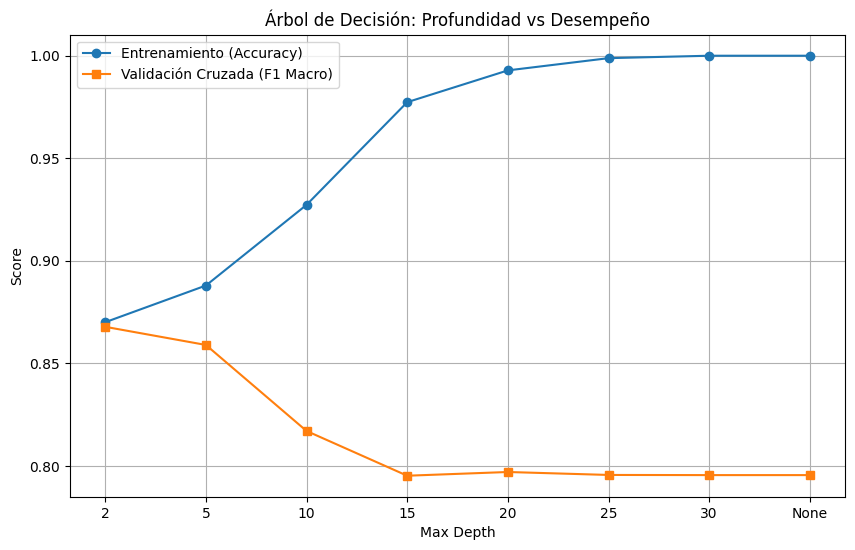

,Profundidad,Accuracy_Train,F1_Macro_CV
0,2,0.870083,0.867831
1,5,0.887962,0.858991
2,10,0.927294,0.817050
3,15,0.977354,0.795238
4,20,0.992849,0.797050
5,25,0.998808,0.795616
6,30,1.000000,0.795540
7,None,1.000000,0.795540


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


X = df.drop('Grade', axis=1)
y = df['Grade']

depths = [2, 5, 10, 15, 20, 25, 30, None]


skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# Entrenamiento y evaluación
train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=3
    )

    # F1 Macro en validación cruzada
    cv_scores = cross_val_score(
        model,
        X,
        y,
        cv=skf,
        scoring='f1_macro'
    )

    test_scores.append(cv_scores.mean())

    # Score de entrenamiento promedio
    model.fit(X, y)

    train_scores.append(
        model.score(X, y)
    )

    print(f"Profundidad: {depth}")
    print(f"F1 Macro CV: {cv_scores.mean():.4f}")
    print("-"*40)


# Gráfica de resultados

labels = ['2', '5', '10', '15', '20', '25', '30', 'None']

plt.figure(figsize=(10,6))

plt.plot(
    labels,
    train_scores,
    marker='o',
    label='Entrenamiento (Accuracy)'
)

plt.plot(
    labels,
    test_scores,
    marker='s',
    label='Validación Cruzada (F1 Macro)'
)

plt.title('Árbol de Decisión: Profundidad vs Desempeño')
plt.xlabel('Max Depth')
plt.ylabel('Score')
plt.grid(True)
plt.legend()

plt.show()

# resumen

resultados = pd.DataFrame({
    'Profundidad': labels,
    'Accuracy_Train': train_scores,
    'F1_Macro_CV': test_scores
})

resultados


El mejor desempeño se obtiene con una profundidad de 2. Conforme aumenta la profundidad del árbol, la exactitud en entrenamiento incrementa hasta alcanzar valores cercanos a 1.0, mientras que el F1 Macro en validación disminuye. Esto indica la presencia de sobreajuste, ya que el modelo aprende excesivamente los datos de entrenamiento y pierde capacidad de generalización.

In [12]:

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

X = df.drop('Grade', axis=1)
y = df['Grade']


dt = DecisionTreeClassifier(random_state=3)



param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}


# Validación cruzada estratificada
skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)


# Random

random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist,
    n_iter=5,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,
    random_state=7
)

# Entrenamiento
random_search.fit(X, y)


print("Mejores hiperparámetros encontrados:")
print(random_search.best_params_)

print("\nMejor F1 Macro:")
print(random_search.best_score_)

Mejores hiperparámetros encontrados:
{'min_samples_split': 9, 'max_depth': 43, 'criterion': 'entropy'}

Mejor F1 Macro:
0.8188758296042687


Los mejores hiperparámetros fueron criterion = entropy, max_depth = 43 y min_samples_split = 9. El mejor desempeño obtenido fue F1 Macro = 0.8189, lo que indica una capacidad de clasificación buena, pero inferior al resultado obtenido en la búsqueda manual de profundidades.

In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold


X = df.drop('Grade', axis=1)
y = df['Grade']

dt = DecisionTreeClassifier(random_state=3)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),          # 5 a 50
    'min_samples_split': range(2, 21)  # 2 a 20
}


skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# Grid Search
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1
)

# Entrenamiento
grid_search.fit(X, y)


# Resultados
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)

print("\nMejor F1 Macro:")
print(grid_search.best_score_)

El mejor conjunto de hiperparámetros encontrado fue criterion = entropy, max_depth = 5 y min_samples_split = 13, obteniendo un F1 Macro de 0.8641. El árbol de profundidad moderada da el mejor equilibrio entre complejidad y capacidad de generalización para la clasificación del grado de glioma.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


X = df.drop('Grade', axis=1)
y = df['Grade']


dt = DecisionTreeClassifier(random_state=3)

param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)


# Randomized Search

random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist,
    n_iter=5,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1,
    random_state=7
)

# Entrenamiento
random_search.fit(X, y)

# Resultados
print("Mejores hiperparámetros encontrados:")
print(random_search.best_params_)

print("\nMejor Accuracy:")
print(random_search.best_score_)

Usando RandomizedSearchCV con la métrica Accuracy, los mejores hiperparámetros fueron criterion = gini, max_depth = 31 y min_samples_split = 10. El modelo tiene una exactitud promedio de 0.8248, lo que indica un buen desempeño general en la clasificación del grado de glioma.

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X = df.drop('Grade', axis=1)
y = df['Grade']

dt = DecisionTreeClassifier(random_state=3)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# Grid
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1
)

# Entrenamiento
grid_search.fit(X, y)

# Resultados
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)

print("\nMejor Accuracy:")
print(grid_search.best_score_)


El mejor modelo encontrado mediante GridSearchCV utilizó criterion = entropy, max_depth = 5 y min_samples_split = 13, alcanzando una Accuracy de 0.8653. Este resultado fue superior al obtenido con RandomizedSearchCV.

1.-GridSearchCV encontró los mejores hiperparámetros tanto para F1 Macro como para Accuracy

2.-GridSearchCV fue mucho más costoso computacionalmente.


3.-Fueron distintos.

RandomizedSearchCV: 0.8189
GridSearchCV: 0.8641

La diferencia se debe a que RandomizedSearchCV solo explora una muestra aleatoria del espaci, por lo que puede no encontrar la mejor combinación. A diferencia de GridSearchCV evalúa todas las combinaciones posibles y garantiza encontrar la mejor configuración.

4.-Fueron distintos.

RandomizedSearchCV: 0.8248
GridSearchCV: 0.8653

La razón es la misma: RandomizedSearchCV analizó únicamente 5 combinaciones aleatorias, mientras que GridSearchCV realizó una búsqueda exhaustiva sobre todo el espacio.

5.- En RandomizedSearchCV los hiperparámetros fueron diferentes para F1 Macro y Accuracy, solo en GridSearchCV fueron iguales.